# Capstone modelling: predicting next-quarter revenue and profit margin

**Question:** using what a company reported up to the end of a quarter, can I predict its **revenue** and **profit margin** for the next quarter?

This notebook continues from `01_EDA_clean final.ipynb` and starts from the cleaned file `clean final.csv`. It follows the decisions recorded in the EDA: time split, MAE as the main metric, GroupKFold by company, median imputation inside the pipeline, and a naive baseline to beat.

Section 7 compares the **three best models** from the course (Lasso, Random Forest, Gradient Boosting), tunes each with `GridSearchCV` and compares them with the baselines on the test set.

## 1. TL;DR

**Three models from the course (Lasso, Random Forest, Gradient Boosting) were tuned with `GridSearchCV` on the same CV folds. Gradient Boosting is the best on both targets: on unseen data it beats naive persistence by 32% for revenue and 23% for margin.**

| Target, test MAE | Null model | Naive persistence (bar to beat) | Lasso | Random Forest | **Gradient Boosting** |
|---|---|---|---|---|---|
| Next quarter log revenue | 0.967 | 0.089 | 0.068 (−24%) | 0.071 (−20%) | **0.060 (−32%)** |
| Next quarter profit margin | 0.095 | 0.060 | 0.053 (−12%) | 0.047 (−21%) | **0.046 (−23%)** |

- **Why these three:** they were the best model of each family (linear, bagging, boosting) when all 13 suitable course regressors were compared in a first round.
- **Choice by train CV only.** The test set (2,055 company-quarters, 2025 to mid-2026) was used once, at the end. CV and test rank the three models the same way.
- **Lasso** already gives most of the gain for revenue (a straight line on good features). **Random Forest** is close to the winner for margin. **Gradient Boosting** wins both.
- **Feature engineering matters more than the choice of model:** without the 5 features built from each company's own history, default Gradient Boosting beats persistence by only 1.6% (revenue) and 8.0% (margin) in CV; with them by 11.0% and 15.0% (section 10).
- Main drivers: this quarter's revenue and last year's seasonal step (revenue); the 4-quarter average margin and this quarter's margin (margin). One-off losses stay unpredictable.

## 2. Recap of the goal

- **Who uses it:** an analyst who wants an early estimate before the next quarterly report is published.
- **One row:** one company in one quarter (`cik` + `period_end`).
- **Targets:**
  - `log_revenue_next`: next quarter revenue, in log (revenue is very right skewed)
  - `profit_margin_next`: next quarter net income / revenue
- **When the prediction is made:** right after quarter *t* is reported, so only values from quarter *t* or earlier can be features.
- **Scope:** non-financial US listed companies (banks, brokers and insurers were excluded in the EDA).

**How I measure success:**
- **MAE** (mean absolute error), lower is better. Margin has long tails and MAE is less sensitive to extremes than RMSE. R² is shown for reference only (for revenue it looks great with any method).
- **Two baselines:** the null model (always the train median) and naive persistence (next quarter = this quarter). A model is useful only if it beats **naive persistence**.
- Models are **chosen only by 5-fold CV on train** (GroupKFold by company). The test set is used once, at the end, to report the result.

## 3. Setup & data loading

Load the libraries and the cleaned table from the EDA. The file `clean final.csv` sits in the project folder; it is written by `01_EDA_clean final.ipynb` (run that notebook first if it is missing). Rows are sorted by company and date, which the lag features in section 4 need.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV, cross_val_score
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

SEED = 50
TARGETS = ["log_revenue_next", "profit_margin_next"]
TEST_START = "2025-01-01"
sns.set_theme(style="whitegrid")

DATA_PATH = "clean final.csv"   # written by 01_EDA_clean final.ipynb
FIG_DIR, OUT_DIR = Path("figures"), Path("outputs")
FIG_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_PATH, parse_dates=["period_end"])
df = df.sort_values(["cik", "period_end"]).reset_index(drop=True)

print(df.shape, "|", df["cik"].nunique(), "companies")
df.head(3)

(11682, 23) | 357 companies


,cik,ticker,company,period_end,calendar_year,calendar_quarter,revenue,net_income,operating_cash_flow,assets,...,log_revenue,log_assets,equity_ratio,cash_ratio,ocf_margin,revenue_growth_qoq,revenue_growth_yoy,log_revenue_next,profit_margin_next,split
0,1800,ABT,ABBOTT LABORATORIES,2018-03-31,2018,1,7.390000e+09,418000000.0,1.108000e+09,7.090800e+10,...,22.723394,24.984649,0.442813,0.054394,0.149932,NaN,NaN,22.773150,0.094374,train
1,1800,ABT,ABBOTT LABORATORIES,2018-06-30,2018,2,7.767000e+09,733000000.0,1.244000e+09,6.841500e+10,...,22.773150,24.948858,0.446934,0.044800,0.160165,0.049756,NaN,22.758755,0.073537,train
2,1800,ABT,ABBOTT LABORATORIES,2018-09-30,2018,3,7.656000e+09,563000000.0,2.183000e+09,7.163700e+10,...,22.758755,24.994878,0.428619,0.102866,0.285136,-0.014394,NaN,22.772892,0.084224,train


## 4. Feature preparation

**Base features** (9, from the EDA, all known at the end of quarter *t*): size (`log_revenue`, `log_assets`), profit and cash (`profit_margin`, `ocf_margin`), balance sheet (`equity_ratio`, `cash_ratio`), growth (`revenue_growth_qoq`, `revenue_growth_yoy`) and season (`calendar_quarter`).

**Feature engineering (FE)**, used by all three models. All new columns use quarter *t* or earlier, so there is no leakage:
- `margin_lag1`: margin one quarter ago
- `margin_mean4`: average margin of the last 4 quarters (the company's "normal" margin)
- `margin_gap`: this margin minus the 4-quarter average. A big negative gap usually means a one-off loss that is likely to recover
- `ocf_gap`: operating cash flow margin minus profit margin. Profit far below cash flow also points to a one-off accounting charge
- `rev_step_last_year`: how log revenue changed from quarter *t−4* to *t−3* last year, i.e. the same seasonal step that is coming next

Lags use `groupby("cik").shift(k)`, as in the course. Some companies have a missing quarter, so the lag is kept only if it really comes from the quarter *k* steps back (checked with a quarter number `q`); otherwise it is set to missing.

**Missing values** are not filled here. They are filled with the **train median plus a missing flag** inside each model's pipeline, so the imputer learns from train only. This step learns nothing from the data, so it can safely run on the full table before the split.

In [2]:
BASE = ["log_revenue", "log_assets", "profit_margin", "ocf_margin", "equity_ratio",
        "cash_ratio", "revenue_growth_qoq", "revenue_growth_yoy", "calendar_quarter"]

# quarter number: one quarter later = +1, one year later = +4
df["q"] = df["calendar_year"] * 4 + df["calendar_quarter"]
by_company = df.groupby("cik")

def lag(col, k):
    """Value of `col` k quarters earlier for the same company (NaN if that quarter is missing)."""
    right_quarter = (df["q"] - by_company["q"].shift(k)) == k
    return by_company[col].shift(k).where(right_quarter)

df["margin_lag1"] = lag("profit_margin", 1)
df["margin_mean4"] = pd.concat([df["profit_margin"], lag("profit_margin", 1),
                                lag("profit_margin", 2), lag("profit_margin", 3)], axis=1).mean(axis=1)
df["margin_gap"] = df["profit_margin"] - df["margin_mean4"]
df["ocf_gap"] = df["ocf_margin"] - df["profit_margin"]
df["rev_step_last_year"] = lag("log_revenue", 3) - lag("log_revenue", 4)

FEATURES = BASE + ["margin_lag1", "margin_mean4", "margin_gap", "ocf_gap", "rev_step_last_year"]

# 'this quarter' version of each target, used by naive persistence
CURRENT = {"log_revenue_next": "log_revenue", "profit_margin_next": "profit_margin"}

print(len(FEATURES), "features | share of missing values:")
df[FEATURES].isna().mean().round(3).sort_values(ascending=False)

14 features | share of missing values:


rev_step_last_year    0.154
revenue_growth_yoy    0.128
cash_ratio            0.089
equity_ratio          0.069
margin_lag1           0.044
revenue_growth_qoq    0.040
ocf_gap               0.019
ocf_margin            0.019
log_revenue           0.000
log_assets            0.000
profit_margin         0.000
calendar_quarter      0.000
margin_gap            0.000
margin_mean4          0.000
dtype: float64

## 5. Train/test split

The same time split as in the EDA (the `split` column): **train** = quarters ending before 2025, **test** = 2025 and later. In real use the model predicts the future from the past; a random split would let it see neighbouring quarters of the same company.

On train I build **5 GroupKFold folds by company** (`cik`): all quarters of one company stay in the same fold, so each fold is scored on companies the model has not seen. The same folds are used by every baseline and model, and for tuning. The test set is used only once, for the final comparison.

In [3]:
train = df[df["split"] == "train"].reset_index(drop=True)
test = df[df["split"] == "test"].reset_index(drop=True)
assert train["period_end"].max() < pd.Timestamp(TEST_START) <= test["period_end"].min()

folds = list(GroupKFold(n_splits=5).split(train, groups=train["cik"]))

print("train:", train.shape, train["period_end"].min().date(), "to", train["period_end"].max().date())
print("test: ", test.shape, test["period_end"].min().date(), "to", test["period_end"].max().date())

train: (9627, 29) 2018-01-26 to 2024-12-31
test:  (2055, 29) 2025-01-24 to 2026-07-05


## 6. Baseline model

Two baselines, no training:
1. **Null model:** `DummyRegressor(strategy="median")` predicts the train median for every row. It ignores the company completely. The median gives the lowest MAE for a constant guess.
2. **Naive persistence:** next quarter = this quarter. An analyst gets this for free, so **this is the bar to beat**.

Each method gets a CV MAE (the same folds as the models) and a test MAE. All results are collected in `results`.

In [4]:
results = []       # one row per (target, method)
predictions = {}   # (target, method) -> test predictions

def add_result(target, name, cv_mae, pred):
    predictions[(target, name)] = pred
    results.append({"target": target, "model": name, "CV MAE": cv_mae,
                    "test MAE": mean_absolute_error(test[target], pred),
                    "test R2": r2_score(test[target], pred)})

for target in TARGETS:
    y = train[target]
    # null model: always the train median (DummyRegressor, as in the course)
    null = DummyRegressor(strategy="median")
    cv = np.mean([mean_absolute_error(y.iloc[va], null.fit(train[FEATURES].iloc[tr], y.iloc[tr]).predict(train[FEATURES].iloc[va]))
                  for tr, va in folds])
    add_result(target, "Null model", cv, null.fit(train[FEATURES], y).predict(test[FEATURES]))
    # naive persistence: next = this quarter
    cv = np.mean([mean_absolute_error(y.iloc[va], train[CURRENT[target]].iloc[va]) for _, va in folds])
    add_result(target, "Naive persistence", cv, test[CURRENT[target]].to_numpy())

pd.DataFrame(results).round(4)

,target,model,CV MAE,test MAE,test R2
0,log_revenue_next,Null model,0.9985,0.9671,-0.1251
1,log_revenue_next,Naive persistence,0.1060,0.0885,0.9847
2,profit_margin_next,Null model,0.0979,0.0950,-0.0405
3,profit_margin_next,Naive persistence,0.0674,0.0600,0.1517


**What the baselines show**
- **Revenue:** persistence (test MAE 0.089, about 9% of revenue) is 91% better than the null model (0.967). Revenue barely moves between quarters, so the bar is high.
- **Margin:** persistence (0.060 = 6.0 pp) is 37% better than the null model (0.095), but its R² is only 0.15: when a margin jumps, "same as last quarter" misses badly. There is more room for a model here.
- CV MAE is higher than test MAE for both baselines because train includes the volatile 2020–2021 period. That is why methods are always compared on the same data: CV with CV, test with test.

## 7. Candidate models

### Why these three models?

The course repository (DSB Unit 03) covers many methods. This is a **regression** problem on a **panel** (357 companies × ~30 quarters) with tabular features, so classification (lessons 08–10), ARIMA/Prophet (one series at a time, too short here; naive persistence is already ARIMA(0,1,0)) and unsupervised methods (clustering, PCA, recommenders) do not fit.

In a first round (a separate exploratory run, not included in this repository) all 13 suitable course regressors were scored on the same features and folds, with default settings except for **Lasso and ElasticNet**: their default penalty (`alpha = 1`) sets almost every coefficient to zero on this data (CV MAE several times worse than persistence), so they were run with a small penalty (`alpha` around 0.001). CV MAE relative to naive persistence (negative = better):

| Model | Revenue | Margin | Average |
|---|---|---|---|
| **Gradient Boosting** | −10.9% | −15.0% | **−12.9%** |
| **Lasso** | −11.9% | −13.0% | **−12.4%** |
| ElasticNet / Linear Regression / Ridge | −11.6% | −13.1% | −12.4% |
| **Random Forest** | −6.3% | −16.1% | **−11.2%** |
| HistGB | −7.6% | −13.9% | −10.8% |
| Bagging, XGBoost, SVR, Decision Tree, KNN, AdaBoost | | | worse (−6.8% to +140%) |

The three kept here are the best of each model family:
1. **Lasso** (linear regression with L1 regularisation, lesson 11). ElasticNet, Linear Regression and Ridge score within 0.1% of it, so one linear model is enough.
2. **Random Forest** (bagging of trees, lesson 21). Best single model for margin.
3. **Gradient Boosting** (boosting, lesson 22). Best average.

Each model is a pipeline: median imputation with a missing flag; for Lasso also `StandardScaler`, because the penalty needs features on the same scale (trees do not need scaling).

In [5]:
models = {
    "Lasso": make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                           StandardScaler(),
                           Lasso(max_iter=10000)),
    "Random Forest": make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                                   RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1)),
    "Gradient Boosting": make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                                       GradientBoostingRegressor(random_state=SEED)),
}
print(list(models))

['Lasso', 'Random Forest', 'Gradient Boosting']


### Tune each model with GridSearchCV

`GridSearchCV` tries every combination in a small grid of settings, for each model and each target, on the same 5 company folds, and keeps the combination with the lowest CV MAE. It then refits that model on all of train. The grids cover the settings from the course:
- **Lasso:** the penalty `alpha` (bigger = simpler model, more coefficients set to zero)
- **Random Forest:** leaf size and the share of features tried at each split (both control overfitting)
- **Gradient Boosting:** number of trees, tree depth, learning rate, row subsampling and the loss (`absolute_error` optimises MAE directly)

Only train is used; the test predictions are stored for section 8. The best CV MAE is the best of the grid, so it is slightly optimistic. This cell takes a few minutes.

In [6]:
grids = {
    "Lasso": {"lasso__alpha": [0.0001, 0.001, 0.01, 0.1]},
    "Random Forest": {"randomforestregressor__min_samples_leaf": [1, 5, 20],
                      "randomforestregressor__max_features": [0.3, 0.5, 1.0]},
    "Gradient Boosting": {"gradientboostingregressor__n_estimators": [200, 400],
                          "gradientboostingregressor__max_depth": [2, 3],
                          "gradientboostingregressor__learning_rate": [0.05, 0.1],
                          "gradientboostingregressor__subsample": [0.7, 1.0],
                          "gradientboostingregressor__loss": ["squared_error", "absolute_error"]},
}

best_models = {}
for target in TARGETS:
    for name, model in models.items():
        search = GridSearchCV(model, grids[name], cv=folds, scoring="neg_mean_absolute_error", n_jobs=-1)
        search.fit(train[FEATURES], train[target])
        best_models[(target, name)] = search.best_estimator_
        add_result(target, name, -search.best_score_, search.best_estimator_.predict(test[FEATURES]))
        print(f"{target} | {name}: CV MAE {-search.best_score_:.4f} | {search.best_params_}")

log_revenue_next | Lasso: CV MAE 0.0933 | {'lasso__alpha': 0.001}


log_revenue_next | Random Forest: CV MAE 0.0994 | {'randomforestregressor__max_features': 1.0, 'randomforestregressor__min_samples_leaf': 5}


log_revenue_next | Gradient Boosting: CV MAE 0.0893 | {'gradientboostingregressor__learning_rate': 0.05, 'gradientboostingregressor__loss': 'absolute_error', 'gradientboostingregressor__max_depth': 2, 'gradientboostingregressor__n_estimators': 400, 'gradientboostingregressor__subsample': 0.7}


profit_margin_next | Lasso: CV MAE 0.0589 | {'lasso__alpha': 0.0001}


profit_margin_next | Random Forest: CV MAE 0.0552 | {'randomforestregressor__max_features': 0.5, 'randomforestregressor__min_samples_leaf': 20}


profit_margin_next | Gradient Boosting: CV MAE 0.0543 | {'gradientboostingregressor__learning_rate': 0.05, 'gradientboostingregressor__loss': 'absolute_error', 'gradientboostingregressor__max_depth': 3, 'gradientboostingregressor__n_estimators': 400, 'gradientboostingregressor__subsample': 0.7}


**What tuning picked**
- **Gradient Boosting:** 400 shallow trees (depth 2 for revenue, 3 for margin), learning rate 0.05, subsampling 0.7 and the `absolute_error` loss, which optimises MAE directly. The same choices for both targets apart from depth.
- **Random Forest:** for margin, large leaves (at least 20 rows) and half of the features at each split. That gives smoother averages that are not pulled by one-off extremes. For revenue: all features, leaves of 5 rows.
- **Lasso:** a small penalty (`alpha` 0.001 for revenue, 0.0001 for margin). With 14 features and ~9,600 rows there is little to regularise.
- **CV ranking:** revenue Gradient Boosting 0.0893 < Lasso 0.0933 < Random Forest 0.0994 (persistence 0.1060); margin Gradient Boosting 0.0543 < Random Forest 0.0552 < Lasso 0.0589 (persistence 0.0674). All three beat persistence on both targets already in CV.

## 8. Evaluation & comparison

The two baselines and the three tuned models on the same test set (2025 onwards). `vs naive %` is the change in test MAE versus naive persistence (negative = better). The **final model per target** is the one with the lowest **CV** MAE, so the test set is still not used for any choice.

In [7]:
res = pd.DataFrame(results)
naive = res[res["model"] == "Naive persistence"].set_index("target")["test MAE"]
res["vs naive %"] = ((res["test MAE"] / res["target"].map(naive) - 1) * 100).round(1)
res = res.sort_values(["target", "test MAE"]).round(4)
res.to_csv(OUT_DIR / "model_results.csv", index=False)

best = res[res["model"].isin(models)].sort_values("CV MAE").groupby("target")["model"].first().to_dict()
print("final model per target (lowest CV MAE):", best)
res

final model per target (lowest CV MAE): {'log_revenue_next': 'Gradient Boosting', 'profit_margin_next': 'Gradient Boosting'}


,target,model,CV MAE,test MAE,test R2,vs naive %
6,log_revenue_next,Gradient Boosting,0.0893,0.0600,0.9921,-32.2
4,log_revenue_next,Lasso,0.0933,0.0677,0.9913,-23.5
5,log_revenue_next,Random Forest,0.0994,0.0706,0.9901,-20.2
1,log_revenue_next,Naive persistence,0.1060,0.0885,0.9847,0.0
0,log_revenue_next,Null model,0.9985,0.9671,-0.1251,992.8
9,profit_margin_next,Gradient Boosting,0.0543,0.0459,0.5117,-23.5
8,profit_margin_next,Random Forest,0.0552,0.0474,0.4965,-21.1
7,profit_margin_next,Lasso,0.0589,0.0527,0.4575,-12.2
3,profit_margin_next,Naive persistence,0.0674,0.0600,0.1517,0.0
2,profit_margin_next,Null model,0.0979,0.0950,-0.0405,58.2


**Chart 1: test MAE.** The null model is left out (far off the scale). Grey = naive persistence, the bar to beat.

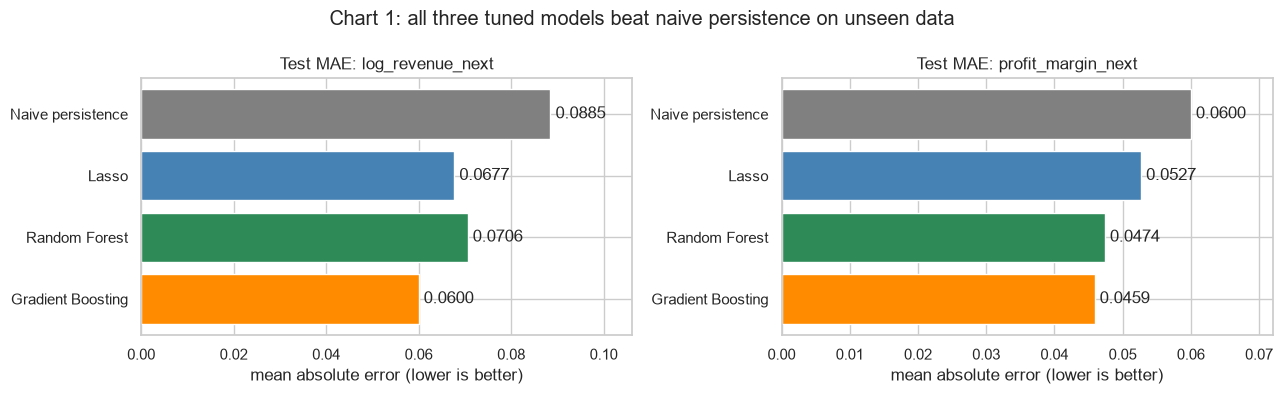

In [8]:
ORDER = ["Naive persistence", "Lasso", "Random Forest", "Gradient Boosting"]
COLORS = ["grey", "steelblue", "seagreen", "darkorange"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, target in zip(ax, TARGETS):
    mae = res[res["target"] == target].set_index("model").loc[ORDER, "test MAE"]
    a.barh(ORDER, mae, color=COLORS)
    for i, v in enumerate(mae):
        a.text(v, i, f" {v:.4f}", va="center")
    a.invert_yaxis()
    a.set_xlim(0, mae.max() * 1.2)
    a.set_title(f"Test MAE: {target}")
    a.set_xlabel("mean absolute error (lower is better)")
fig.suptitle("Chart 1: all three tuned models beat naive persistence on unseen data")
fig.tight_layout()
fig.savefig(FIG_DIR / "07a_test_mae.png", dpi=120)
plt.show()

**Chart 2: CV vs test.** Each method scored in CV on train (light) and on the test set (dark). If the order of the models is the same in both, the result is reliable and not a lucky test period. CV MAE is higher than test MAE for every method because train includes the volatile 2020–2021 period.

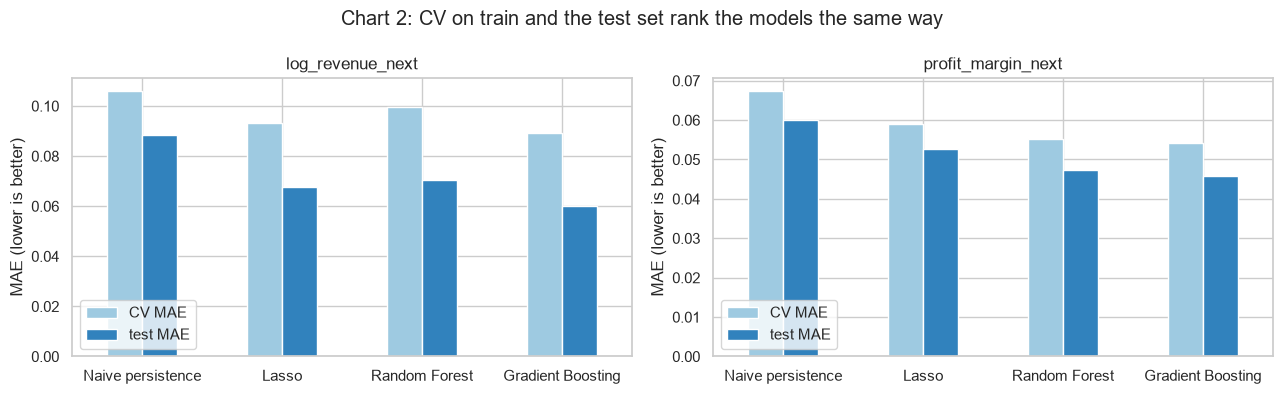

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, target in zip(ax, TARGETS):
    r = res[res["target"] == target].set_index("model").loc[ORDER, ["CV MAE", "test MAE"]]
    r.plot(kind="bar", ax=a, color=["#9ecae1", "#3182bd"], rot=0)
    a.set_title(target)
    a.set_xlabel("")
    a.set_ylabel("MAE (lower is better)")
    a.legend(loc="lower left")
fig.suptitle("Chart 2: CV on train and the test set rank the models the same way")
fig.tight_layout()
fig.savefig(FIG_DIR / "07b_cv_vs_test.png", dpi=120)
plt.show()

**Chart 3: error over time.** Test MAE per quarter of the test period. It shows whether the gain over persistence holds in every quarter or comes from one period only.

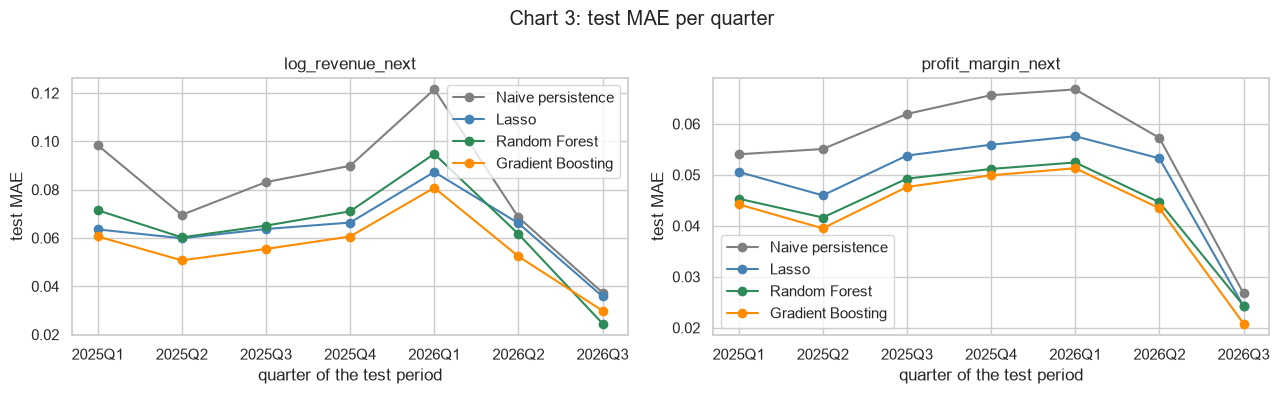

In [10]:
quarter = test["period_end"].dt.to_period("Q").astype(str)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, target in zip(ax, TARGETS):
    for name, color in zip(ORDER, COLORS):
        error = (test[target] - predictions[(target, name)]).abs()
        error.groupby(quarter).mean().plot(ax=a, marker="o", color=color, label=name)
    a.set_title(target)
    a.set_xlabel("quarter of the test period")
    a.set_ylabel("test MAE")
    a.legend()
fig.suptitle("Chart 3: test MAE per quarter")
fig.tight_layout()
fig.savefig(FIG_DIR / "07c_error_over_time.png", dpi=120)
plt.show()

**Chart 4: share of good predictions.** The share of test rows where the prediction is close to the truth: within 0.05 in log revenue (about 5% of revenue) and within 0.03 in margin (3 percentage points).

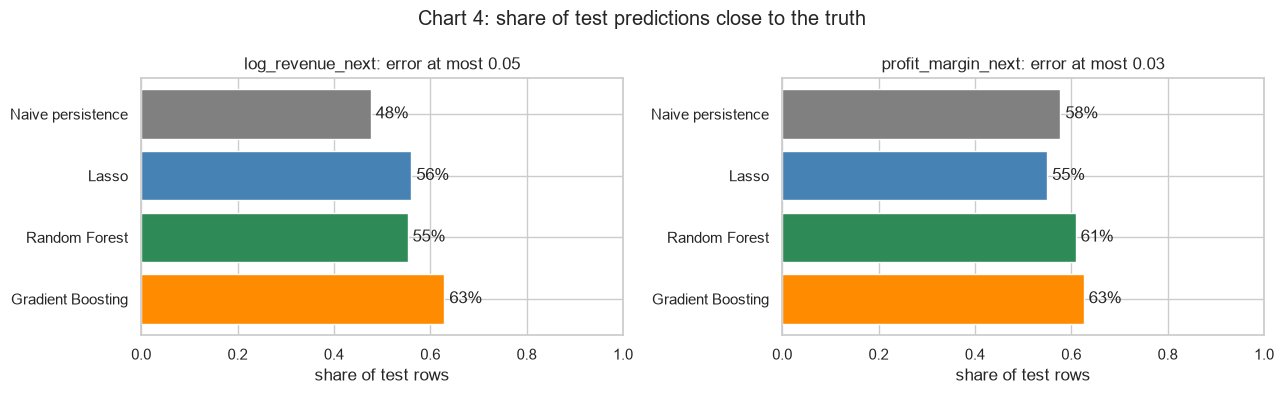

In [11]:
LIMIT = {"log_revenue_next": 0.05, "profit_margin_next": 0.03}

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, target in zip(ax, TARGETS):
    share = [((test[target] - predictions[(target, name)]).abs() <= LIMIT[target]).mean() for name in ORDER]
    a.barh(ORDER, share, color=COLORS)
    for i, v in enumerate(share):
        a.text(v, i, f" {v:.0%}", va="center")
    a.invert_yaxis()
    a.set_xlim(0, 1)
    a.set_title(f"{target}: error at most {LIMIT[target]}")
    a.set_xlabel("share of test rows")
fig.suptitle("Chart 4: share of test predictions close to the truth")
fig.tight_layout()
fig.savefig(FIG_DIR / "07d_share_close.png", dpi=120)
plt.show()

**What the comparison shows**
- **Gradient Boosting is the best model on both targets, in CV and on test.** Revenue: test MAE 0.060 vs 0.089 for persistence (−32%). Margin: 0.046 vs 0.060 (−23%), and R² rises from 0.15 to 0.51.
- **Lasso** is second for revenue (−24%): next quarter's revenue is almost a straight line of this quarter plus the seasonal step. For margin it is the weakest of the three (−12%), because margin depends on non-linear effects (a loss quarter is followed by a recovery, but not in a straight line).
- **Random Forest** is the opposite: close to Gradient Boosting for margin (−21%) but third for revenue (−20%). Averages of trees cannot reproduce a near 1:1 straight line precisely.
- **Chart 3:** all three models beat persistence in every test quarter. Gradient Boosting has the lowest error in every quarter except the last point (2026Q3), which has only 6 rows and is not reliable.
- **Chart 4:** for revenue, 63% of Gradient Boosting predictions are within 0.05 (about 5% of revenue), vs 48% for persistence. For margin, 63% are within 3 percentage points (Random Forest 61%, persistence 58%). Lasso has *fewer* close margin predictions than persistence (55%): it pulls each company towards the average, so its gain comes only from avoiding the big misses.

## 9. Error analysis

Where does the best model for each target (chosen by CV) go wrong? First predicted vs actual: points on the red line are perfect predictions.

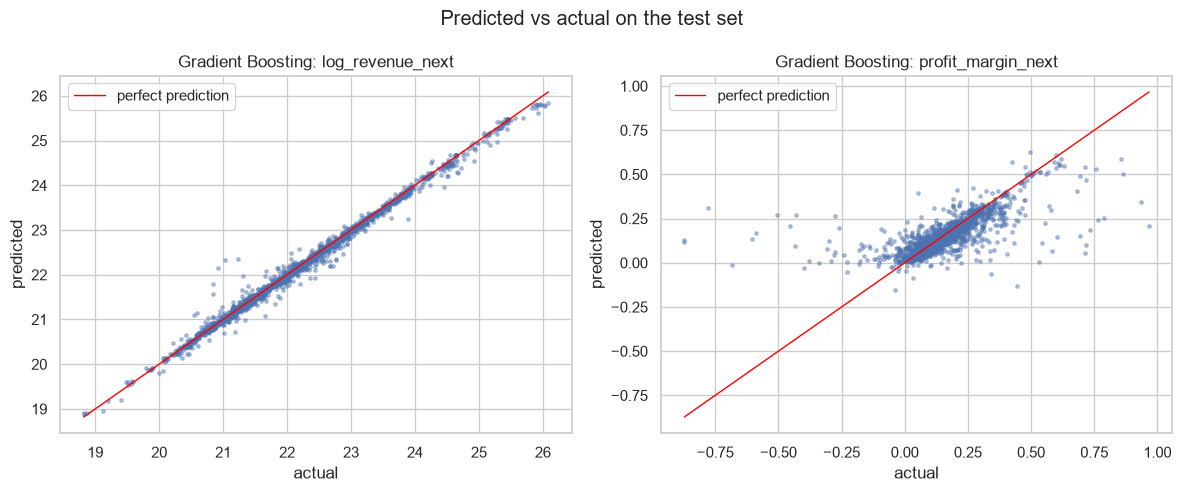

In [12]:
err = test[["ticker", "company", "period_end", "log_revenue", "profit_margin"] + TARGETS].copy()
for target in TARGETS:
    err[f"pred_{target}"] = predictions[(target, best[target])]
    err[f"err_{target}"] = (err[target] - err[f"pred_{target}"]).abs()

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, target in zip(ax, TARGETS):
    a.scatter(err[target], err[f"pred_{target}"], s=6, alpha=0.4)
    lo, hi = err[target].min(), err[target].max()
    a.plot([lo, hi], [lo, hi], color="red", lw=1, label="perfect prediction")
    a.set_title(f"{best[target]}: {target}")
    a.set_xlabel("actual")
    a.set_ylabel("predicted")
    a.legend()
fig.suptitle("Predicted vs actual on the test set")
fig.tight_layout()
fig.savefig(FIG_DIR / "08_pred_vs_actual.png", dpi=120)
plt.show()

Error by company size: test rows are split into five equal groups by this quarter's revenue, and the mean absolute error is computed in each group.

In [13]:
err["size_group"] = pd.qcut(err["log_revenue"], 5, labels=["1 smallest", "2", "3", "4", "5 largest"])
err.groupby("size_group", observed=True)[[f"err_{t}" for t in TARGETS]].mean().round(4)

,err_log_revenue_next,err_profit_margin_next
size_group,,
1 smallest,0.0490,0.0552
2,0.0589,0.0492
3,0.0707,0.0419
4,0.0603,0.0377
5 largest,0.0613,0.0457


The ten largest margin misses, to see what kind of events the model cannot predict.

In [14]:
cols = ["ticker", "company", "period_end", "profit_margin", "profit_margin_next",
        "pred_profit_margin_next", "err_profit_margin_next"]
err.sort_values("err_profit_margin_next", ascending=False)[cols].head(10).set_index(["ticker", "company", "period_end"]).round(3)

,,,profit_margin,profit_margin_next,pred_profit_margin_next,err_profit_margin_next
ticker,company,period_end,,,,
DOC,"Healthpeak Properties, Inc.",2025-06-30,0.213,-0.778,0.311,1.090
HAS,"HASBRO, INC.",2025-03-30,0.111,-0.873,0.130,1.003
KHC,Kraft Heinz Co,2026-03-28,0.132,-0.872,0.119,0.991
INCY,INCYTE CORPORATION,2026-06-30,0.350,-0.504,0.269,0.773
DOC,"Healthpeak Properties, Inc.",2025-12-31,0.732,0.966,0.206,0.761
IVZ,Invesco Ltd.,2025-09-30,0.217,-0.589,0.167,0.756
GPN,GLOBAL PAYMENTS INC.,2025-12-31,0.113,-0.606,0.136,0.742
FANG,"Diamondback Energy, Inc.",2025-09-30,0.259,-0.432,0.270,0.702
INTC,Intel Corporation,2026-03-28,-0.275,-0.684,-0.011,0.673


**What the errors show** (Gradient Boosting, the final model for both targets)
- **Predicted vs actual:** revenue sits tightly on the diagonal. For margin most points are close, but sudden losses (left) and unusually high margins (right) are pulled back towards the company's normal level.
- **Company size:** margin errors are largest for the smallest companies (5.5 pp) and smallest for mid-to-large ones (3.8–4.2 pp). For revenue the smallest companies are the easiest (0.049) and the middle group the hardest (0.071).
- **The largest misses are one-off events:** a sudden large loss (e.g. Healthpeak, Hasbro, Kraft Heinz, Incyte, Global Payments) or the quarter right after such an event (Healthpeak appears twice: a large loss, then a large gain). In almost all of them the current margin was normal, so nothing in the accounting data warned of the shock.

## 10. Interpretation

**Permutation importance** on the test set for the best model per target: shuffle one feature at a time and measure how much MAE grows. A big increase means the model relies on that feature.

log_revenue_next top 3: {'log_revenue': 1.2534, 'rev_step_last_year': 0.0422, 'log_assets': 0.0057}


profit_margin_next top 3: {'margin_mean4': 0.0334, 'profit_margin': 0.0217, 'margin_lag1': 0.0039}


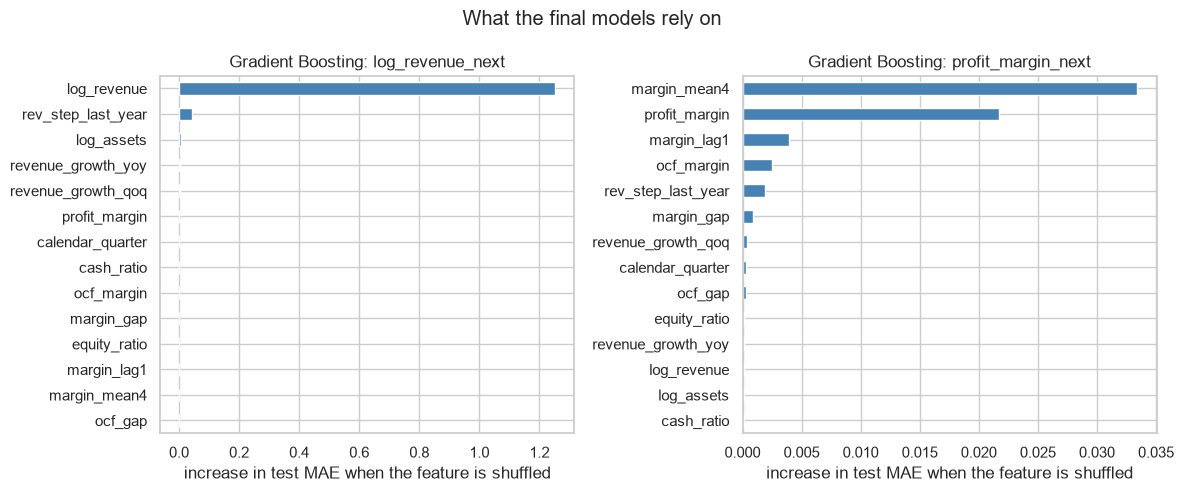

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, target in zip(ax, TARGETS):
    imp = permutation_importance(best_models[(target, best[target])], test[FEATURES], test[target], n_repeats=5,
                                 scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=-1)
    s = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
    s.plot(kind="barh", ax=a, color="steelblue")
    a.set_title(f"{best[target]}: {target}")
    a.set_xlabel("increase in test MAE when the feature is shuffled")
    print(target, "top 3:", s.sort_values(ascending=False).head(3).round(4).to_dict())
fig.suptitle("What the final models rely on")
fig.tight_layout()
fig.savefig(FIG_DIR / "09_feature_importance.png", dpi=120)
plt.show()

**In plain terms**
- **Revenue:** the model starts from "next quarter ≈ this quarter" (`log_revenue` dominates by far). Second comes the engineered feature `rev_step_last_year`: *if revenue jumped into this season last year, it will probably do so again*. This seasonal correction is the main source of the gain over persistence. Company size (`log_assets`) adds a small correction.
- **Margin:** the model relies most on the company's **4-quarter average margin** (`margin_mean4`), then on this quarter's and last quarter's margin. In words: *next quarter's margin lies between this quarter and the company's normal level*. A one-off bad quarter is therefore expected to recover, which persistence cannot do.
- The other features add much less (see the chart).

### Do the engineered features matter?

The same two default models (Linear Regression and Gradient Boosting, no tuning) are scored in CV on train twice: with the 9 base features only, and with the 5 engineered features added. `vs naive %` is the change in CV MAE versus naive persistence (negative = better). Only train is used.

In [16]:
ablation = []
for target in TARGETS:
    y = train[target]
    naive_cv = np.mean([mean_absolute_error(y.iloc[va], train[CURRENT[target]].iloc[va]) for _, va in folds])
    candidates = {
        "Linear Regression": make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                                           StandardScaler(), LinearRegression()),
        "Gradient Boosting": make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                                           GradientBoostingRegressor(random_state=SEED)),
    }
    for name, model in candidates.items():
        for label, cols in [("1 base (9)", BASE), ("2 base + engineered (14)", FEATURES)]:
            cv = -cross_val_score(model, train[cols], y, cv=folds,
                                  scoring="neg_mean_absolute_error", n_jobs=-1).mean()
            ablation.append({"target": target, "model": name, "features": label,
                             "vs naive %": (cv / naive_cv - 1) * 100})

ablation = pd.DataFrame(ablation).pivot_table(index=["target", "model"], columns="features",
                                              values="vs naive %").round(1)
ablation

features                              1 base (9)  2 base + engineered (14)
target             model                                                  
log_revenue_next   Gradient Boosting        -1.6                     -11.0
                   Linear Regression        -3.6                     -11.6
profit_margin_next Gradient Boosting        -8.0                     -15.0
                   Linear Regression        -2.3                     -12.7

**What the ablation shows**
- With the base features only, both models are barely better than persistence (−1.6% to −8.0%).
- Adding the 5 features from each company's own history brings them to about −11% to −15%, for both targets and both models.
- So most of the gain comes from **how the company's history is turned into features** (seasonal step, normal margin), not from the choice of algorithm.

## 11. Limitations & ethics

- **Non-financial companies only.** Banks, brokers and insurers were excluded in the EDA, so the model does not apply to them.
- **Extreme quarters were removed.** Margins outside −100% to +100% were set to missing in the EDA (e.g. cruise lines in 2020–21). The model has not seen the worst crises and will underestimate them. The same filter also removed them from the **test set** (rows whose next-quarter margin is outside ±100%), so the test MAE describes normal and moderately bad quarters, not crises.
- **Large US listed companies only** (S&P 500 snapshot). Results may not hold for small, private or non-US companies.
- **Survivorship bias.** The company list is a recent snapshot, so firms that failed or were delisted are missing and the data look more stable than reality.
- **Short test period.** About six quarters (2025 to mid-2026); one unusual period can move the scores.
- **Tuning CV is slightly optimistic.** The CV MAE of the tuned models is the best of the grid on the same folds. The test MAE is the honest number.
- **Three models only.** They were picked from a first round with default settings (a small penalty for Lasso and ElasticNet); a model that did badly there (e.g. SVR, KNN) might do better with tuning.
- **Only accounting data.** No sector, macro data, guidance or news, which explain most large surprises (write-downs, mergers).
- **Use with care.** Predictions support an analyst's judgement and should not be the only basis for credit, investment or audit decisions. Errors are largest for one-off events, exactly where decisions matter most.

## 12. Conclusion & next steps

**What worked**
- All three tuned models beat naive persistence on unseen 2025–2026 data, for both targets and in every test quarter.
- **Gradient Boosting** is the final model: **−32% error for revenue, −23% for margin** versus persistence, chosen by train CV and confirmed on test.
- Simple engineered features (last year's seasonal step, 4-quarter average margin) brought most of the gain, for every model: without them default Gradient Boosting beats persistence by only 1.6% (revenue) and 8.0% (margin) in CV, with them by 11.0% and 15.0% (section 10).

**What did not work**
- Lasso is weak for margin (only −12%) and has fewer close margin predictions than persistence.
- Random Forest is weak for revenue compared with the other two.
- No model predicts large one-off losses; they cause most of the remaining margin error.

**Next steps**
1. **Add context the accounting data lacks:** sector from the SEC SIC code, simple macro data (rates, GDP growth) and the company's own guidance, which explain most large surprises.
2. **Check stability over time:** repeat the test with a rolling time split (`TimeSeriesSplit`, train on earlier years, test on the next year) instead of one 2025–2026 test period.
3. **Use and monitor:** retrain the Gradient Boosting pipeline every quarter on all data, save it with `joblib`, and track test MAE against naive persistence; if the gain disappears, retrain or revisit features.
4. **Extend the scope:** a separate model for banks and insurers with their own revenue definition, and prediction intervals so the analyst sees how uncertain each estimate is.



## 13. Appendix: libraries, course code and data sources

Everything used in this notebook, with links, so the work can be checked and repeated.

**Libraries**
- pandas (data loading, cleaning, groupby and shift): https://pandas.pydata.org/docs/
- NumPy (log transform, arrays): https://numpy.org/doc/stable/
- matplotlib (charts): https://matplotlib.org/stable/
- seaborn (scatter plots, heatmap, theme): https://seaborn.pydata.org/
- scikit-learn (models, pipelines, tuning, metrics): https://scikit-learn.org/stable/
  - `DummyRegressor`: https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html
  - `Lasso`: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html
  - `LinearRegression` (feature ablation): https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html
  - `cross_val_score` (feature ablation): https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html
  - `RandomForestRegressor`: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html
  - `GradientBoostingRegressor`: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html
  - `GridSearchCV`: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
  - `GroupKFold`: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupKFold.html
  - `SimpleImputer`: https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html
  - `StandardScaler`: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
  - `make_pipeline`: https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html
  - `mean_absolute_error`: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_absolute_error.html
  - `r2_score`: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html
  - `permutation_importance`: https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html

Versions used: pandas 3.0.5 and NumPy 2.5.3 (printed in the EDA notebook).

**Course code this notebook follows** (General Assembly DSB)
- Unit 3, lesson 04: regression metrics (MAE, R², null model): https://github.com/CharleyHananiaGA/DSB-Unit-03/blob/main/04%20-%20Regression%20Metrics/02-regression-metrics.ipynb
- Unit 3, lesson 05: train/test split and cross-validation: https://github.com/CharleyHananiaGA/DSB-Unit-03/blob/main/05%20-%20Model%20Generalizability/02-train-test-split-cross-validation.ipynb
- Unit 3, lesson 11: regularisation (Lasso, scaling before the penalty): https://github.com/CharleyHananiaGA/DSB-Unit-03/blob/main/11%20-%20Regularization/02-regularization.ipynb
- Unit 3, lesson 12: pipelines and GridSearchCV: https://github.com/CharleyHananiaGA/DSB-Unit-03/blob/main/12%20-%20Grid%20Search%20and%20Pipelines/02-gridsearch-pipelines.ipynb
- Unit 3, lesson 13: model interpretation: https://github.com/CharleyHananiaGA/DSB-Unit-03/blob/main/13%20-%20Model%20Interpretation/02-model-explainability.ipynb
- Unit 3, lesson 21: random forests, gradient boosting regressor, permutation importance: https://github.com/CharleyHananiaGA/DSB-Unit-03/blob/main/21%20-%20Bootstrapping%20Bagging%20and%20Random%20Forests/03-ensemble-models-live.ipynb
- Unit 3, lesson 22: boosting: https://github.com/CharleyHananiaGA/DSB-Unit-03/blob/main/22%20-%20Boosting/02-ensembles-boosting.ipynb
- Unit 3 glossary: null model (baseline) for regression: https://github.com/CharleyHananiaGA/DSB-Unit-03/blob/main/Readme.MD#null-model-baseline-for-regression
- Unit 3 glossary: mean absolute error (MAE): https://github.com/CharleyHananiaGA/DSB-Unit-03/blob/main/Readme.MD#mean-absolute-error-mae
- Unit 3 glossary: other cross-validation schemes (GroupKFold): https://github.com/CharleyHananiaGA/DSB-Unit-03/blob/main/Readme.MD#other-cross-validation-schemes
- Unit 3 glossary: permutation importance: https://github.com/CharleyHananiaGA/DSB-Unit-03/blob/main/Readme.MD#permutation-importance
- Unit 3 glossary: capstone playbook (modelling stage): https://github.com/CharleyHananiaGA/DSB-Unit-03/blob/main/Readme.MD#s38-capstone-playbook
- EDA and cleaning: see the Appendix of `01_EDA_clean final.ipynb`

**Data**
- SEC EDGAR application programming interfaces (Company Facts API, quarterly figures from 10-Q and 10-K filings): https://www.sec.gov/search-filings/edgar-application-programming-interfaces
- SEC rules for accessing EDGAR data: https://www.sec.gov/search-filings/edgar-search-assistance/accessing-edgar-data
- Files in this repository: raw download `raw_data_400.csv` (400 companies, built on 9 November 2026), cleaned table `clean final.csv` (written by `01_EDA_clean final.ipynb`, section 8, and read by `02_modelling_.ipynb`).
- SEC EDGAR data is public U.S. government information. It contains company figures only, no personal data.

**Capstone guidelines:** https://github.com/juanatga/ga_capstone_guideline_dsb